In [2]:
import math

In [6]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad=0.0
        self._backward=lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # we want to set out backward to be the function that propagate the gradient
        # for us to be able to do:  for eg object + digit [a + 1] -> the line of code below is necesaary
        other=other if isinstance(other, Value) else Value(other)
        out=Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad+=1.0 * out.grad
            other.grad+=1.0 * out.grad
        out._backward=_backward
        
        return out
        

    def __mul__(self, other):
        other=other if isinstance(other, Value) else Value(other)
        out=Value(self.data * other.data, (self, other), '*')
        def _backward():
            # chain rule
            self.grad+=other.data * out.grad
            other.grad+=self.data * out.grad
        out._backward=_backward
        return out
    def __neg__(self):
        return self * -1
    def __sub__(self, other):
        # addition of negation, annd we have to impelemtn negation above
        return self + (-other)
        
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only support int/float power for now"
        out=Value(self.data**other, (self,), f'**{other}')
        return out

        def _backward():
            self.grad+= other*(self.data**(other-1)) * out.grad # exercise
        out._backward=_backward
    #  fall back for digit * a:
    def __rmul__(self, other):  # other * self
        return self * other
    # implement the right hand add:
    def __radd__(self, other):
        return self + other

    # divsion
    def __truediv__(self, other):
       return self * other ** -1

    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out=Value(t, (self,), 'tanh')
        def _backward():
            # chain rule
            self.grad+= (1-t**2)*out.grad
        out._backward=_backward
        return out
        # topological graph  for backprop
    # write e(x) method:
    def exp(self):
        x=self.data
        out=Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad+=out.data * out.grad
        out.backward=_backward
        return out
    def backward(self):
        topo=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad=1.0
        for node in reversed(topo):
            node._backward()
        
        

Python evaluates self * other ** -1 in two steps, and the missing return breaks the first one quietly, so the error shows up in the second.

Take b / a:

Python calls b.__truediv__(a), so inside it self is b and other is a.
** binds tighter than *, so other ** -1 runs first. That is a.__pow__(-1). This part runs without any error. It computes 2.0 ** -1 = 0.5, builds out, and defines _backward. Then the function ends with no return, so Python hands back None.
The expression is now effectively b * None, which calls b.__mul__(None).
In __mul__, None is not a Value, so it gets wrapped as Value(None).
The next line computes self.data * other.data, which is 3.0 * None, and that raises:

In [18]:
a=Value(2.0)
b=Value(3.0)

# 3*a
# b + 4
# b/a
a-b

# solve this witrh r.mul()..if python an't do 3*a then it falls back to 
# rmul automaticall
# 3.mul(a)

Value(data=-1.0)

In [21]:
a=Value(2.0)
a.exp()
print(a.exp())



Value(data=7.38905609893065)


In [29]:
# Visualizing the expression graph
from graphviz import Digraph

In [14]:
from graphviz import Digraph

def trace(root):
    """Walk backwards from root, collecting every node and edge."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # left to right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # a box showing the label and the value
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # a small extra node for the operation (+ or *)
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect the child to the operation node of its parent
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
f=Value(-2.0, label='f')
L=d*f; L.label='L'

dot = draw_dot(d)
# dot.render('graph', view=True)   # writes graph.svg and opens it
# In Jupyter, just end the cell with:  draw_dot(d)


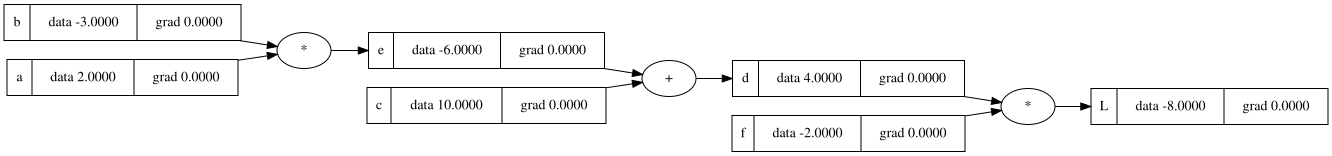

In [26]:
draw_dot(L)

# 00:32:10 manual backpropagation example #1: simple expression

grad==0.0 initially means, the derivative of L with respect to [c, e, d, f]

In [15]:
L.grad=1.0
# dL/df
# L=d*f
# dL/dd=f=-2.0
# dL/df=2*(-3.0) + 10=4
d.grad=2.0
f.grad=4
dL/de=?
we know how L changed with respect to d and f, but not how it did so wrt to e and f directly, but there is a relationship between d and e, itmeans e got to be related to L

de/dd?
dL/de=yes
dL/de?
dL/de=dL/de * de/dd
# same thing applies by symmetry

SyntaxError: cannot assign to expression (2995469354.py, line 8)

In [16]:
# starting from L, if change L with a tiny amount h, how much does L, change?
# changes by h, its propotional and ther derivative will eb one


def lol():
    h=0.001
    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L1=L.data

    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L2=L.data +h

    print((L2-L1)/h)
# lol()
# derivative of a with respect to L   becuae a is the one we bump by h

In [40]:
lol()

1.000000000000334


In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

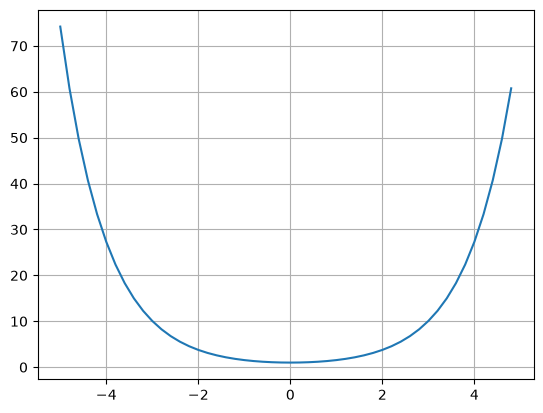

In [26]:
# reak backpropagation

plt.plot(np.arange(-5, 5, 0.2), np.cosh(np.arange(-5, 5, 0.2))); plt.grid();

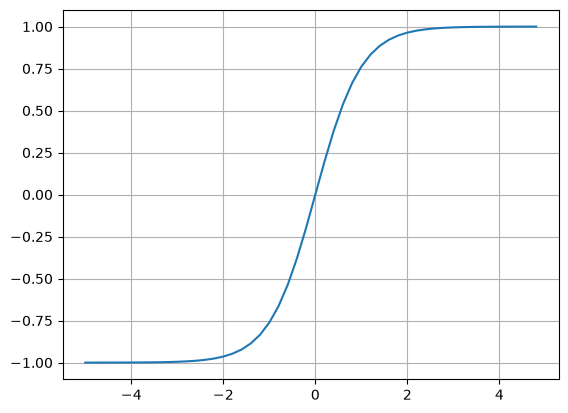

In [7]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

In [18]:
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#  weigghts [w1, w2]
w1=Value(-3.0, label='w1')
w2=Value(1.0,  label='w2')
# biase of the neuron:
b=Value(6.88137335070195432, label='b')
# x1w1 + x2w2 + b
x1w1=x1*w1;  x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1 + x2w2; x1w1x2w2.label='x1w1x2w2'
n=x1w1x2w2 + b; n.label='n'
o=n.tanh(); o.label="o"
o.backward()

In [19]:
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#  weigghts [w1, w2]
w1=Value(-3.0, label='w1')
w2=Value(1.0,  label='w2')
# biase of the neuron:
b=Value(6.88137335070195432, label='b')
# x1w1 + x2w2 + b
x1w1=x1*w1;  x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1 + x2w2; x1w1x2w2.label='x1w1x2w2'
n=x1w1x2w2 + b; n.label='n'

# ----- change how we define o

# o=(e**2x-1)/(e**2x + 1)
e=(2*n).exp();
o=(e-1)/(e+1)

# o=n.tanh(); o.label="o"
o.label='o'
o.backward()

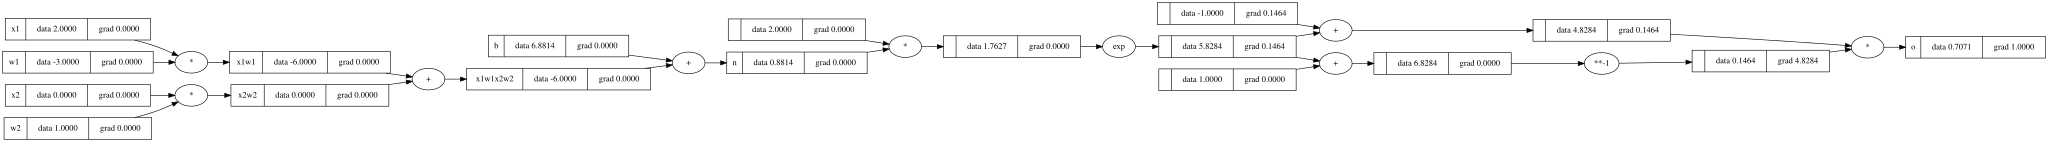

In [21]:
draw_dot(o)

In [22]:
print("__")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())

__


AttributeError: 'float' object has no attribute 'item'

In [46]:
o.backward()

In [40]:
# IMPLEMENTING TOPOLOGICAL SORT
o.grad=1.0
# you are only going to be on the list, once all your children are kin the list
topo=[]
visited=set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

for node in reversed(topo):
    node._backward()

In [41]:
# IMPLEMENTING TOPOLOGICAL SORT
o.grad=1.0
# you are only going to be on the list, once all your children are kin the list
topo=[]
visited=set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.8813733507019545),
 Value(data=0.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813733507019545),
 Value(data=0.7071066630277335)]

In [42]:
o.grad=1.0


In [43]:
o._backward()

In [39]:
n._backward()

In [30]:
b._backward()

In [43]:
x1w1x2w2._backward()

In [45]:
x2w2._backward()

In [47]:
x1w1._backward()

In [61]:
# calculate the gradient of x2, w2, x1, w1
# chain rule in practice
x2.grad=w2.data * x2w2.grad
w2.grad=x2.data * x2w2.grad

In [52]:
x1w1.grad=0.5
x2w2.grad=0.5

In [50]:
x1w1x2w2.grad=0.5
b.grad=0.5

In [49]:
# lets know the local derivative of tanhx
# o=tanh(n)
n.grad=0.5
o.grad=1.0



# do/dn=1-tanh(n)**2
# 1-n**2
o.data
1-o.data**2


# A plus is just a distributor of gradient __  so after the  "+" 
# symbo,distributor,  do/dn=0.5, so distributing to x2w2 and x1w1 will be
#  1*do/dn=0.5 and 1* do/dn=0.5, 1 is as result of 1=dn/dx1w1x2w2 and so on..

# so x1w1x2w2.grad=0.5
# same for  b.grad=0.5
# same distribution law for: x1w1 and x2w2
# pluses are favorite to backprop through because they are simple

0.5000001671017833

# BUG TO SOLVE

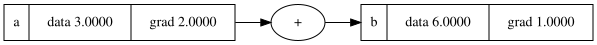

In [44]:
a=Value(3.0, label="a")
b=a+a; b.label='b'
# gradient for db/da= is sppose to be 2. but we goinging to  gegt 1: why??
# becuase self.data == other.data ==1, we get the gradient overrriden
b.backward()
draw_dot(b)


# ANOTHER WAY TO SEE IT IN A MORE COMPLICATED EXPRESSSION
<!-- when we back prop  -->
when a variable is used more than once
multivariate case of tbe chain rule

there is a problem at the level  of redistributing the gradient at the (+) and (*) : at the level of e wrt a and b it get redistributed adn then computing d wrt to b and a it the previous one is overriden
. That is a bug to solve

# SOlution is to accumulate the gradient from the chain rule :
self.data+=other.grad

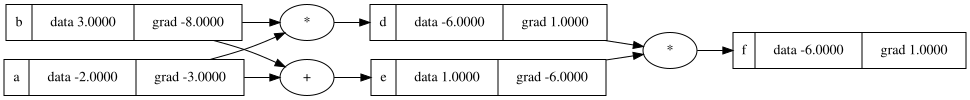

In [45]:
a=Value(-2.0, label='a')
b=Value(3.0, label='b')
e=a+b; e.label='e'
d=a*b; d.label='d'
f=d*e; f.label='f'

f.backward()
draw_dot(f)

# implementing tanh from scratch

In [ ]:
WRITE A DIV METHOD:

# a/b
# =a*(1/b)
# a*b^-1
# so the other
# so we doing x**k for some constant k
# which is perfectly differentiable
# so we will implement the power function

# Doing it the pytorch way

In [23]:
import torch
# double- > we want to have float 64, because they are leavenots by default pytorch assumes they o not reuire gradient, so wwe set requires_grad=True
x1=torch.Tensor([2.0]).double() ; x1.requires_grad=True
x2=torch.Tensor([0.0]).double() ; x2.requires_grad=True
w1=torch.Tensor([-3.0]).double(); w1.requires_grad=True
w2=torch.Tensor([1.0]).double(); w2.requires_grad=True
b=torch.Tensor([16.8813735878195532]).double(); b.requires_grad=True
n=x1*w1 + x2*w2 + b
o=torch.tanh(n)

# print(o.data.item())
o.backward()

In [24]:
print("__")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())

__
x2 1.414550032163204e-09
w2 0.0
x1 -4.243650096489612e-09


# CODING AN ACTUAL NEURON

In [7]:
import random
import math
# import math
class Neuron:
    def __init__(self, nin):
        self.w=[Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1, 1))

    def __call__(self, x):
        # w*x + b -> generator operator
        act=sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        # pass through non linearity and return act.tanh()
        out=act.tanh()
        return out
x=[1.0, 3.0, 4.0]
n=Neuron(3)
n(x)

Value(data=0.9999491858249211)

## Creating a Layer OF Neuron

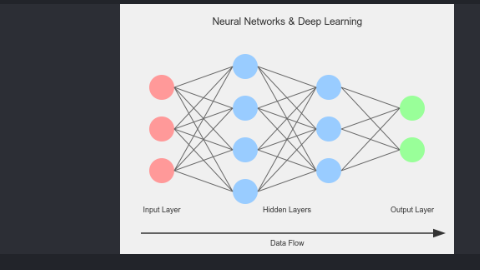

In [21]:
# a layer is just a list of neurons
class Layer:
    def __init__(self, nin, nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]
    def __call__(self, x):
        out=[n(x) for n in self.neurons]
        return out
    def print_result(self):
        print(f"number of neurons {self.neurons}")
x=[2.0, 3.0, 4.0]
n=Layer(3, 4)
n(x)
# n.print_result()

[Value(data=0.999994526686777),
 Value(data=0.9996787049831601),
 Value(data=-0.18946663693817506),
 Value(data=-0.7050968645791938)]

# MULTI LAYER PERCEPTRON MLP:


In [22]:
class MLP:
    def __init__(self, nin, nouts):
        sz=[nin] + nouts
        self.layers=[Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x=layer(x)
        return x

x=[2.0, 3.0, -1.0]
n=MLP(3, [4, 4, 1])
n(x)

[Value(data=-0.7801245540595882)]